# 🔍 ChurnShield AI — Explicabilidade do Modelo (SHAP)

**Objetivo:** Entender o que o modelo aprendeu e como cada feature contribui para as predições.

**Técnicas:**
- SHAP Summary Plot (importância global)
- SHAP Force Plot (explicação individual)
- SHAP Dependence Plot (relação feature × impacto)
- Análise de casos: clientes de alto e baixo risco

In [1]:
import sys
sys.path.append('..')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import shap
import yaml

from lightgbm import LGBMClassifier
from src.data.data_loader import ChurnDataLoader
from src.features.feature_engineering import build_feature_pipeline, apply_smote

shap.initjs()

with open('../config/config.yaml') as f:
    CONFIG = yaml.safe_load(f)

print('✅ Pronto!')

✅ Pronto!


In [2]:
# Preparar dados e modelo
loader = ChurnDataLoader(CONFIG)
df = loader.load(use_synthetic=True)
X_train, X_test, y_train, y_test = loader.get_splits(df)

pipeline = build_feature_pipeline(CONFIG)
X_train_fe = pipeline.fit_transform(X_train, y_train)
X_test_fe = pipeline.transform(X_test)
X_train_res, y_train_res = apply_smote(X_train_fe, y_train)

# LightGBM como modelo base para SHAP (TreeExplainer)
model = LGBMClassifier(
    n_estimators=300, num_leaves=63, learning_rate=0.05,
    random_state=42, verbose=-1
)
model.fit(X_train_res, y_train_res)
print(f'✅ Modelo treinado!')

# Nomes das features
n_features = X_train_fe.shape[1]
feature_names = [f'feature_{i}' for i in range(n_features)]

2026-04-26 01:03:17.347 | INFO     | src.data.data_loader:load:267 - Arquivo não encontrado. Usando dataset sintético...
2026-04-26 01:03:17.348 | INFO     | src.data.data_loader:generate_synthetic_dataset:50 - Gerando dataset sintético com 7,043 amostras...
2026-04-26 01:03:17.375 | SUCCESS  | src.data.data_loader:generate_synthetic_dataset:158 - Dataset gerado: 7,043 linhas | 21 colunas | Churn rate: 22.1%
2026-04-26 01:03:17.405 | INFO     | src.data.data_loader:load:271 - Dataset salvo em: data\raw\churn_data.csv
2026-04-26 01:03:17.415 | INFO     | src.data.data_loader:load:280 - Data hash: becc0750
2026-04-26 01:03:17.420 | SUCCESS  | src.data.data_loader:validate:226 - ✅ Validação de dados: PASSOU em todas as verificações
2026-04-26 01:03:17.428 | INFO     | src.data.data_loader:get_splits:330 - Split: train=5,634 | test=1,409 | churn_train=22.0% | churn_test=22.1%
2026-04-26 01:03:17.430 | INFO     | src.features.feature_engineering:build_feature_pipeline:271 - Pipeline de feat

✅ Modelo treinado!


## 1. SHAP TreeExplainer

In [3]:
# Calcular valores SHAP
explainer = shap.TreeExplainer(model)
shap_values = explainer.shap_values(X_test_fe)

# Para classificação binária, pega classe positiva
if isinstance(shap_values, list):
    sv = shap_values[1]
else:
    sv = shap_values

print(f'Shape dos SHAP values: {sv.shape}')
print('✅ SHAP calculado!')

Shape dos SHAP values: (1409, 32)
✅ SHAP calculado!


c:\Users\kaiow\Desktop\git\ChurnShield\.venv\Lib\site-packages\shap\explainers\_tree.py:448: UserWarning: LightGBM binary classifier with TreeExplainer shap values output has changed to a list of ndarray
  warnings.warn('LightGBM binary classifier with TreeExplainer shap values output has changed to a list of ndarray')


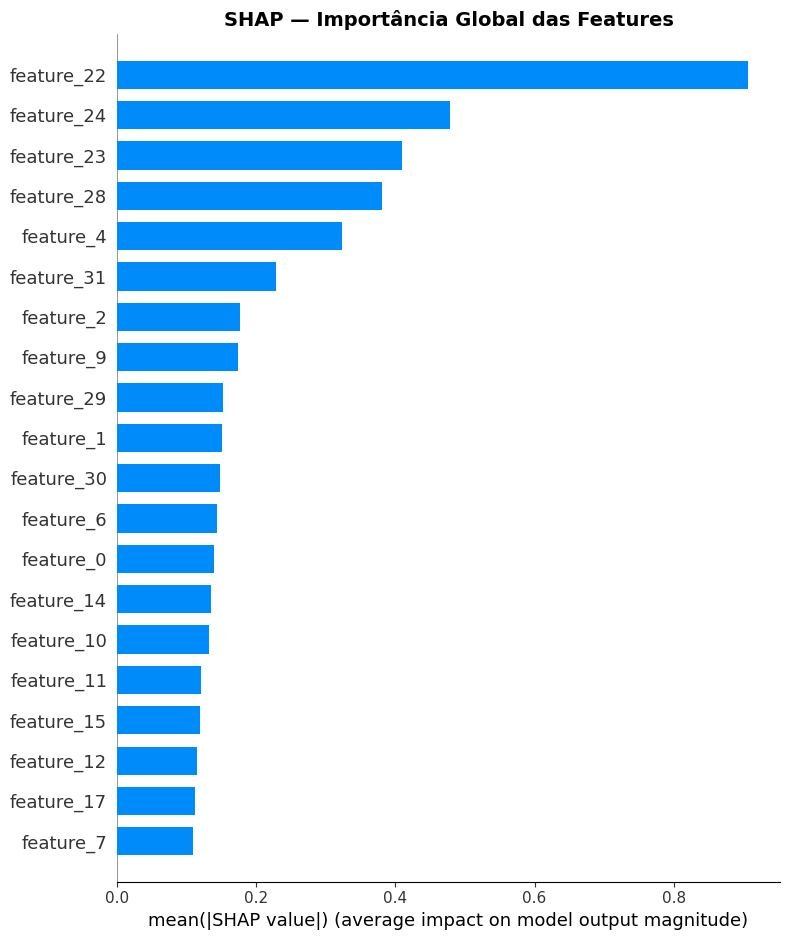

📊 Figura salva!


In [4]:
# Summary Plot — importância global
plt.figure(figsize=(10, 8))
shap.summary_plot(
    sv, X_test_fe,
    feature_names=feature_names,
    plot_type='bar',
    show=False
)
plt.title('SHAP — Importância Global das Features', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('../reports/figures/shap_summary.png', dpi=150, bbox_inches='tight')
plt.show()
print('📊 Figura salva!')

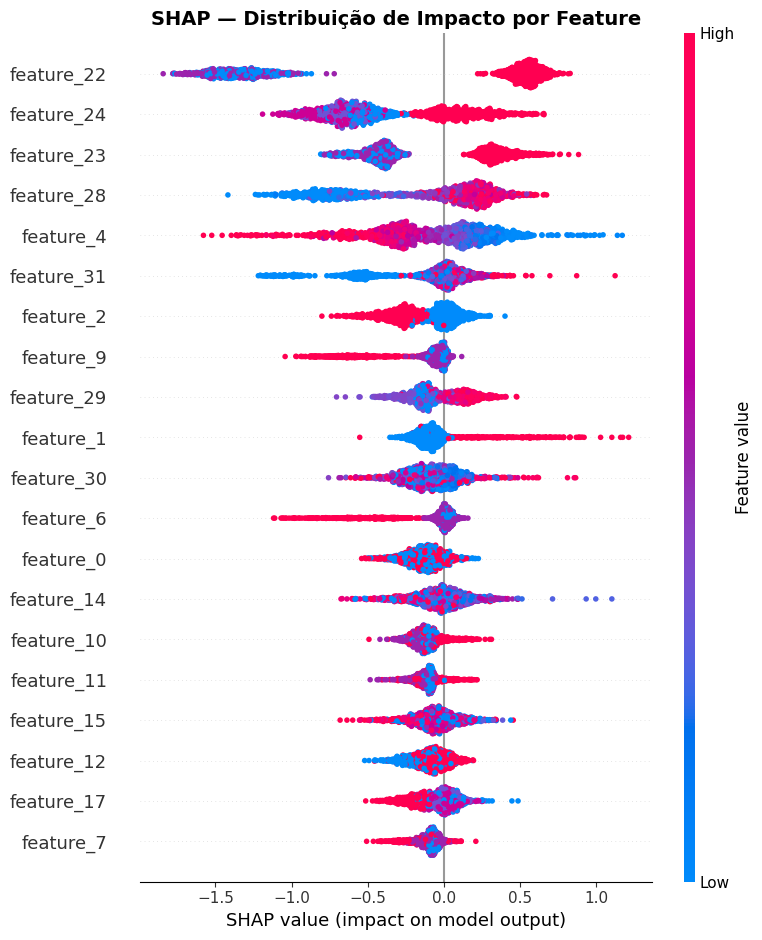

In [5]:
# Summary Plot com distribuição (beeswarm)
plt.figure(figsize=(10, 8))
shap.summary_plot(sv, X_test_fe, feature_names=feature_names, show=False)
plt.title('SHAP — Distribuição de Impacto por Feature', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

## 2. Explicação Individual — Cliente de Alto Risco

In [6]:
# Encontrar cliente com maior probabilidade de churn
probs = model.predict_proba(X_test_fe)[:, 1]
high_risk_idx = np.argmax(probs)
low_risk_idx = np.argmin(probs)

print(f'Cliente de MAIOR risco — índice {high_risk_idx}: P(churn) = {probs[high_risk_idx]:.3f}')
print(f'Cliente de MENOR risco — índice {low_risk_idx}: P(churn) = {probs[low_risk_idx]:.3f}')

Cliente de MAIOR risco — índice 459: P(churn) = 0.991
Cliente de MENOR risco — índice 5: P(churn) = 0.001


🔴 Explicação — Cliente de ALTO RISCO:


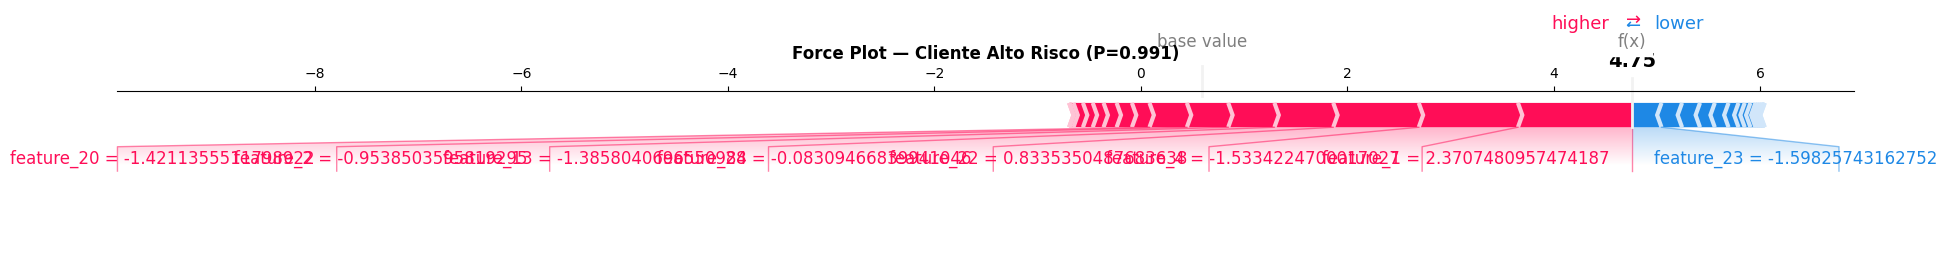

In [7]:
# Force plot — cliente de alto risco
print('🔴 Explicação — Cliente de ALTO RISCO:')
shap.force_plot(
    explainer.expected_value[1] if isinstance(explainer.expected_value, list) else explainer.expected_value,
    sv[high_risk_idx],
    X_test_fe[high_risk_idx],
    feature_names=feature_names,
    matplotlib=True,
    show=False
)
plt.title(f'Force Plot — Cliente Alto Risco (P={probs[high_risk_idx]:.3f})', fontweight='bold')
plt.tight_layout()
plt.show()

## 3. Conclusões de Explicabilidade

### 🔍 O que o SHAP nos diz:

1. **contract_risk** é consistentemente o preditor mais forte — clientes mensais têm SHAP positivo alto
2. **tenure** tem efeito protetor — quanto mais tempo, menor o SHAP value (reduz risco)
3. **monthly_charges** alto aumenta o risco de churn
4. **internet_risk** (fibra) contribui positivamente para churn
5. **online_security** e **tech_support** quando ausentes aumentam o risco

### 💡 Valor de negócio:
Com SHAP, o time de negócio pode entender **por que** cada cliente foi classificado como risco, permitindo ações de retenção mais precisas e personalizadas.